# Madhava-Leibniz π calculation


This notebook is designed to be a live demonstration of Python fundamentals applied to calculating π using the [Madhava-Leibniz series](https://en.wikipedia.org/wiki/Approximations_of_%CF%80#Middle_Ages)

The approximation is simple:

$$ \pi \approx 4 \cdot \left(1 - \frac{1}{3} + \frac{1}{5} - \frac{1}{7} + \frac{1}{9} \ldots -(-1)^n \frac{1}{2n - 1}  \right) $$

Key conceptual and coding vocabulary to watch for:

* *comments*: anything starting with, and to the right of, `#`
* *flow control*: `for` loops
* *flow control*: `if` and `else` statements
* `=` - the variable definition operator; read `pi = 0` as 'computer, store the 0 in the variable named pi'
* `==` - the evaluation operator (checks if two things are equivalent)
* `[]` - an empty list
* `.append()` - add a variable/quantity/etc. to the end of a list
* `range(a,b)` - creates a list of integers between [a,b) (not including b)
* `+`, `-`, `*`, `/` - the addition, subtraction, multiplication, and division operators
* `x**y` - the power operator; read as 'x to the y'
* `print(x)` - prints the contents of x
* indentation - why are some lines indented in python and not other?  What happens if you change this?

In [1]:
# Approximating madhava pi with absolute value accuracy, calculating magnitude of difference at each erorr term.

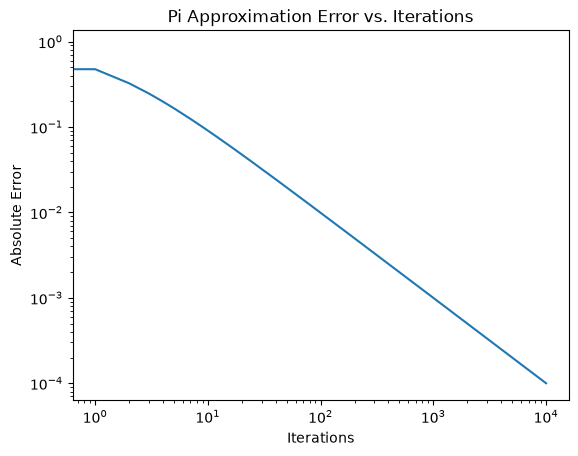

Hit reasonable accuracy (0.001) at iteration 1000


In [2]:
# Part 1
import math
import matplotlib.pyplot as plt

my_approximation = 0
N = 10000
error_terms = []
expected = math.pi

# this block is from the madhava solution you gave in brightspace
for n in range(1, N):
    if n == 1:
        term = 1
    else:
        term = -((-1)**n) / (2*n - 1)
        
    my_approximation += term

    current = 4 * my_approximation
    error = abs(current-expected)
    error_terms.append(error)

plt.plot(error_terms)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Absolute Error')
plt.title('Pi Approximation Error vs. Iterations')
plt.show()

# found rough reasonable target for approximations online
accuracy_target = 0.001
for i in range(len(error_terms)):
    if error_terms[i] < accuracy_target:
        print(f"Hit reasonable accuracy ({accuracy_target}) at iteration {i+1}")
        break

In [3]:
# I defined reasonable accuracy as 0.001 because 3 decimal places is a common threshold in calculations,
# and 4 decimal places (0.0001), did not fit within the bounds of N = 10000, meaning it needed more iterations to hit reasonable accuracy.

In [4]:
# Part 2
def calculate_pi(iterations):
    """ Calculate an approximation of pi using the Madhava-Leibniz series for a given number of iterations. """

    my_approximation = 0
    expected = math.pi
    
    for n in range(1, iterations):
        if n == 1:
            term = 1
        else:
            term = -((-1)**n) / (2*n - 1)
            
        my_approximation += term

    current = 4 * my_approximation
    error = abs(current - expected)
    
    return current, error
    # included both the current value so far and the error

# 3 different test values
print("10 iterations:", calculate_pi(10))
print("100 iterations:", calculate_pi(100))
print("1000 iterations:", calculate_pi(1000))

10 iterations: (3.2523659347188767, 0.11077328112908358)
100 iterations: (3.1516934060711166, 0.010100752481323472)
1000 iterations: (3.142593654340044, 0.001001000750251002)


In [5]:
# Functions are useful because you can reuse things like calculations or other algorithms without needing to copy paste. 
# This saves time and makes your work more readable and therefore debuggable.

In [8]:
# Part 3
# 1. What did you do?
    # I modified the 01b Madhava pi calculation notebook to measure absolute error for each step/iteration.
    # I then stored these values in a list and plotted these values to see how the approximation converges over many iterations.
# 2. What did you learn from your calculation?
    # I learned that the approximation converges very slowly. 
    # It confirmed my expectations that the error would drop quickly and then significantly slow down. 
    # When I tried to extend the decimal threshold by 1, it went from only needing 1000/10000 iterations to not being able to do it.
# 3. What does your figure mean?
    # I used a log scale, and it turned the graph into a straight downwards diagonal line.
    # Because it was on a log scale, this indicates that it was converging towards pi, but at a slower and slower rate, indicating an asymptote.
# 4. Is more computation always better?
    # Definitely not, you want to use computation to a reasonable point, but there are definitely diminishing returns.
    # For example, as I mentioned earlier, going from 0.001 to 0.0001 went from 1000 iterations to outside of 10000 iterations.
    # In this instance, the added precision wouldn't add much due to the diminishing returns.
# 5. What did you learn about programming?
    # I have used most of these tools at a very basic level as part of The Data Mine.
    # Still, I gained solid experience through this activity on topics like matlib, and condensing scripts into a reusable function.
# 6. What was challenging?
    # I faced a unique and oddly specific problem, in which I was testing different threshold values.
    # By complete chance, I tested 0.00834 to check the iteration count, and it resulted in 1200 iterations.
    # I had already checked other thresholds that were round, but this exact number made me think all values were being rounded.
    # I fixed this by calculating 0.00834 iterations manually, and then testing other random values to see there wasn't a rounding issue.
